In [ ]:
! pip install digital_twinning

In [28]:
import digital_twinning as dt
import numpy as np
from uncertain_variables import *
import pandas as pd

In [29]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [30]:
variables = np.load("mosaic_toy_6_variables_samples.npy")
frequencies = np.load("mosaic_toy_6_variables_frequencies.npy")
eigenvectors = np.load("mosaic_toy_6_variables_eigenvectors.npy")

In [31]:
P1 = Variable('m', UniformDistribution(0.5, 1.5))
P2 = Variable('j', UniformDistribution(0.5, 1.5))
P3 = Variable('k1', UniformDistribution(0.5, 1.5))
P4 = Variable('k2', UniformDistribution(0.5, 1.5))
P5 = Variable('l1', UniformDistribution(0.5, 1.5))
P6 = Variable('l2', UniformDistribution(0.5, 1.5))

Q = VariableSet()
Q.add(P1)
Q.add(P2)
Q.add(P3)
Q.add(P4)
Q.add(P5)
Q.add(P6)
QoI_names = ['f.1', 'f.2', 'S.1.1.x', 'S.1.2.x', 'S.2.1.x', 'S.2.2.x']

In [32]:
X_train = pd.DataFrame(variables, columns=['m', 'j', 'k1', 'k2', 'l1', 'l2'])
eigenvectors = eigenvectors.reshape(eigenvectors.shape[0], -1)
QoI_df = pd.DataFrame(np.concatenate((frequencies, eigenvectors), axis=1), columns=QoI_names)

In [33]:
model = dt.MOSAIC(Q, QoI_names)

In [34]:
X_train, X_test, y_train, y_test = model.train_test_split(X_train, QoI_df)

In [35]:
model.train(X_train, y_train)

----- Training started for 'MosaicModel' model -----
Number of modes: 2
Mode 1 is trained
Mode 2 is trained
Average train loss: 0.03349308613653, Average valid loss: 0.03437999201027
----- Training ended for MosaicModel model -----


(<Figure size 640x480 with 4 Axes>,
 <Figure size 1800x1800 with 36 Axes>,
 <Figure size 600x600 with 2 Axes>)

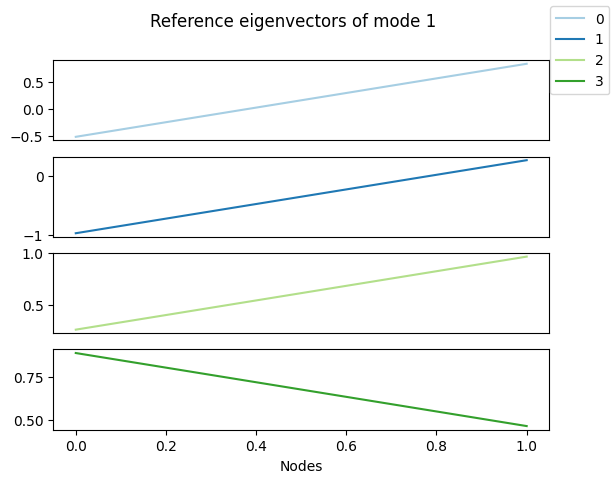

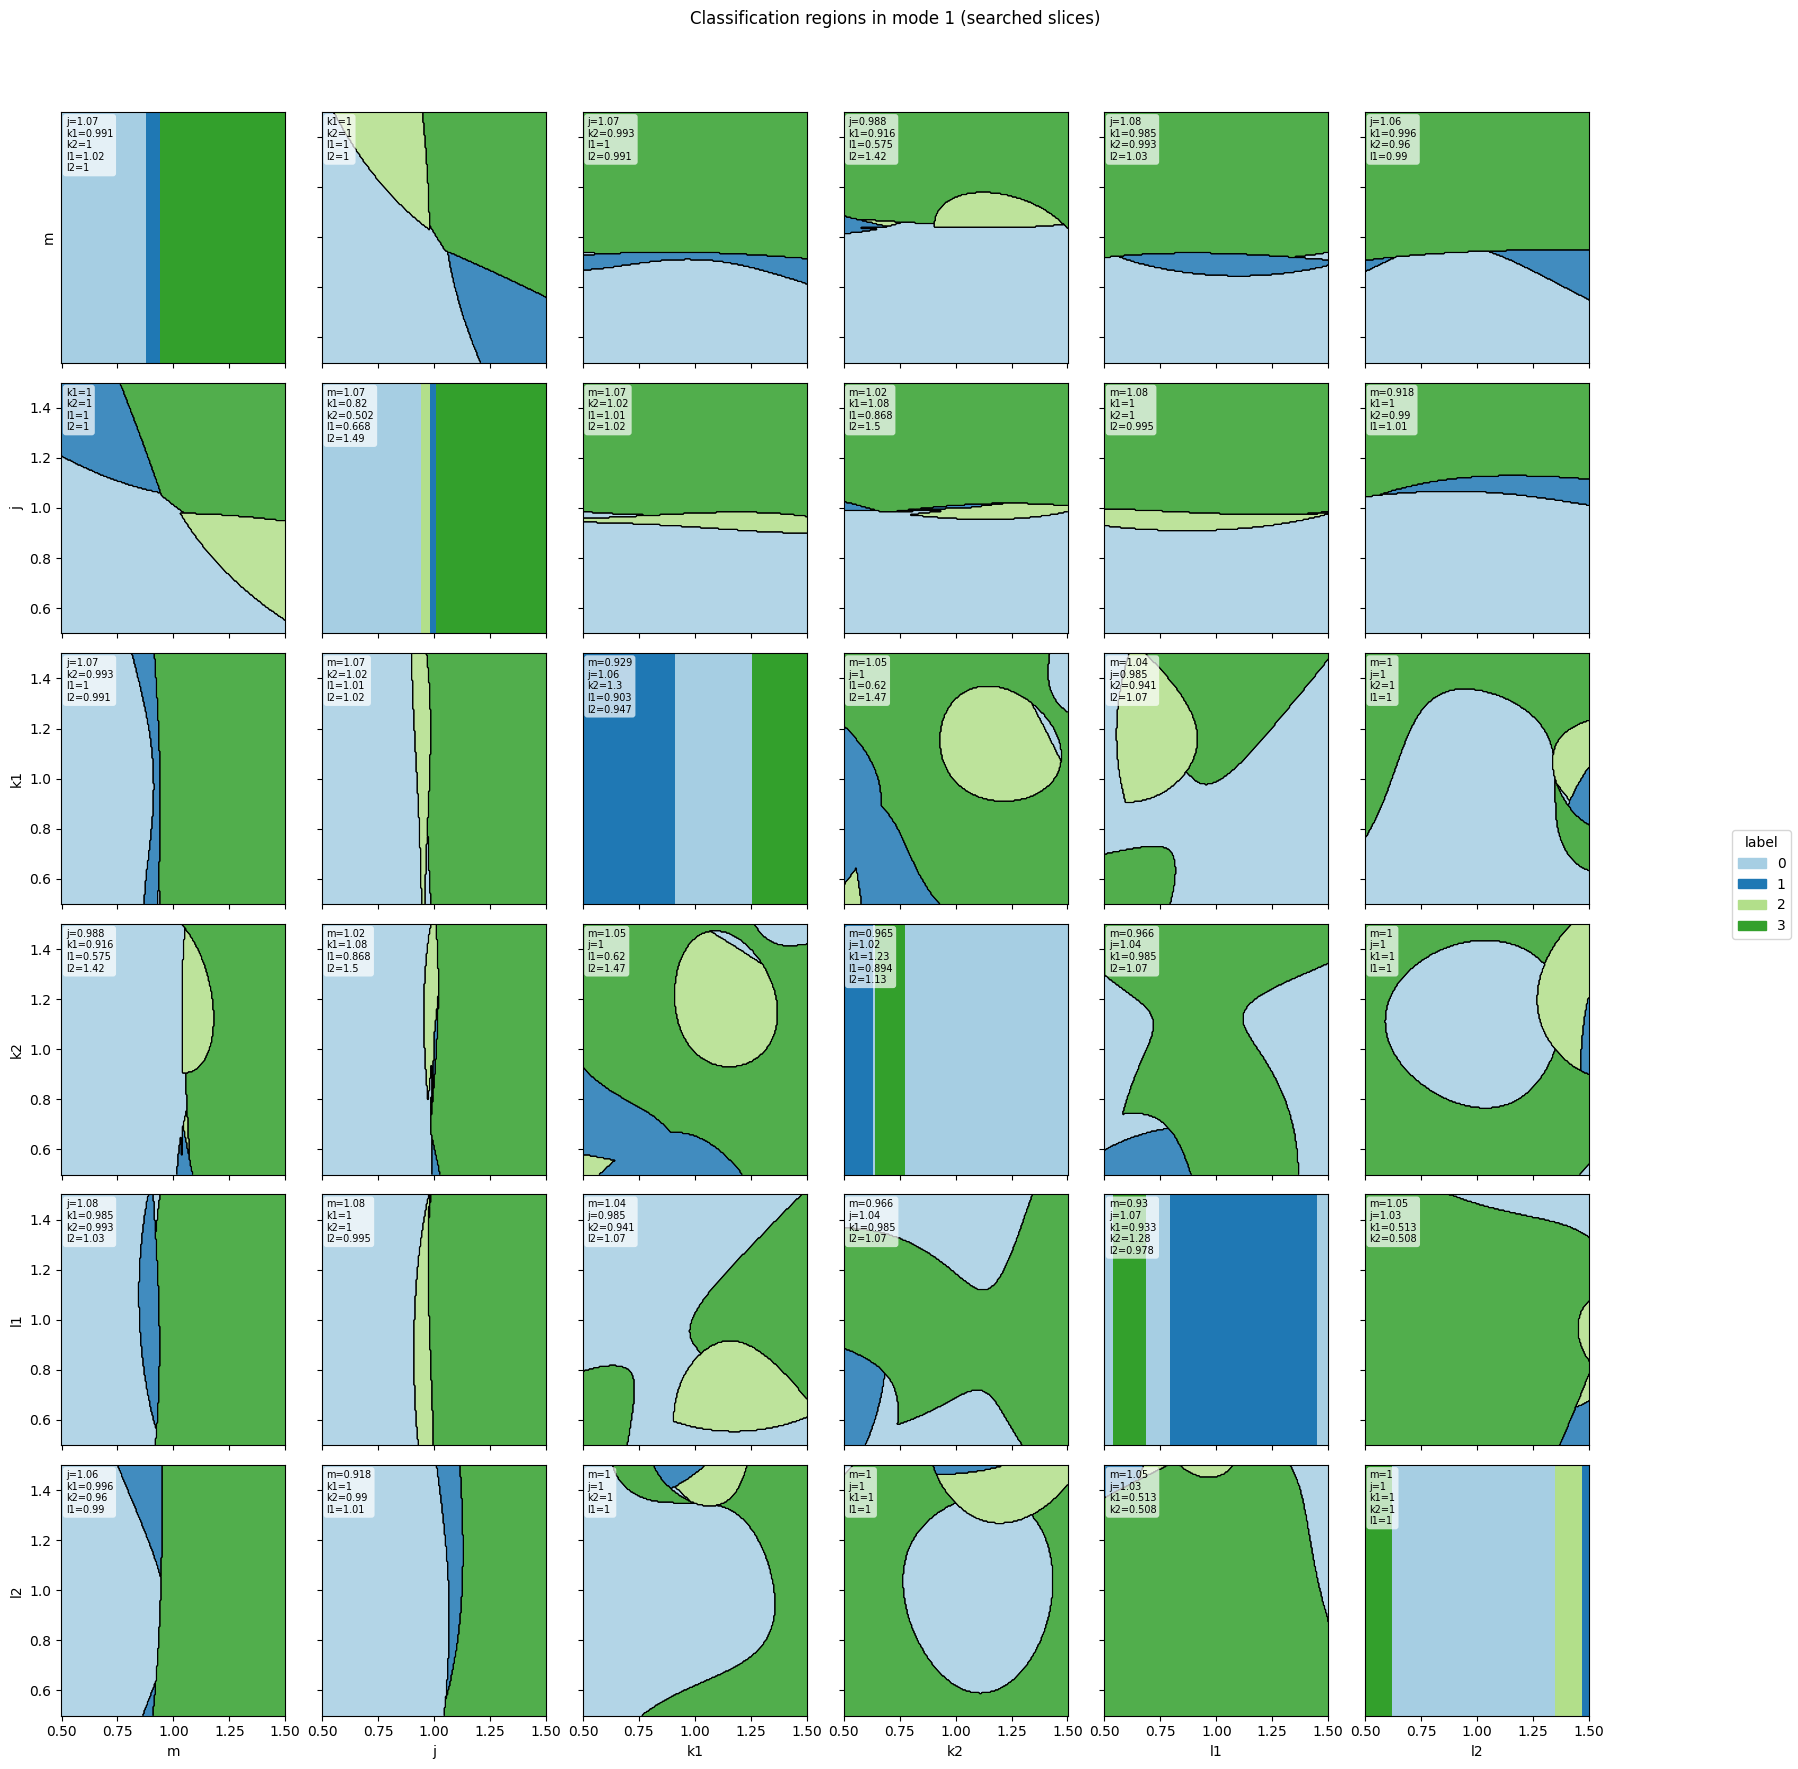

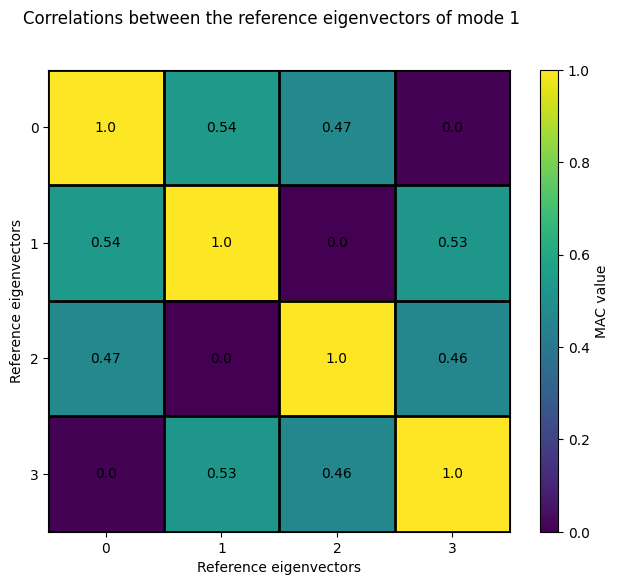

In [37]:
model.plot_variable_space_exploration(mode=1)

In [38]:
# set max_index for Sobol sensitivity analysis
max_index = 2

partial_variance, sobol_index = model.get_sobol_sensitivity(max_index)

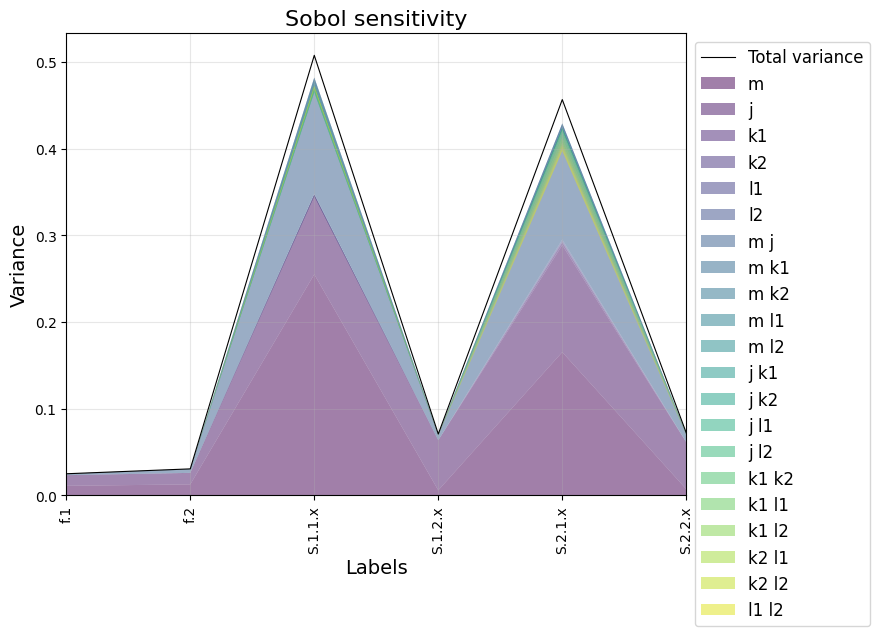

In [39]:
# Plot Sobol Sensitivity Index
# The 'plot_sobol_sensitivity' method generates a plot of Sobol Sensitivity indices, which quantify
# the contribution of each input parameter to the output uncertainty.
# - max_index: Specifies the maximum index of parameters to consider in the plot.
# - param_name: The name of the quantity of interest (QoI) for which sensitivity is being calculated ('t_1' in this case).
fig = model.plot_sobol_sensitivity(y_train, max_index=max_index)


In [40]:
# Calculate SHAP (Shapley Additive Explanations) values
# The 'get_shap_values' method computes the SHAP values for the model's test data (model.X_test).
# SHAP values explain the contribution of each input feature to the prediction for each test sample.
# - model.X_test.iloc[:100]: The first 100 samples from the test set are selected for SHAP value computation.
# SHAP values help to interpret the model's decisions and understand the impact of each input parameter on the output.
shap_values = await model.get_shap_values(X_test, silent=True)


Message: sample size for shap values is set to 100.


In [41]:
q_true_df = pd.read_csv('mosaic_q_true_df_toy_6.csv')

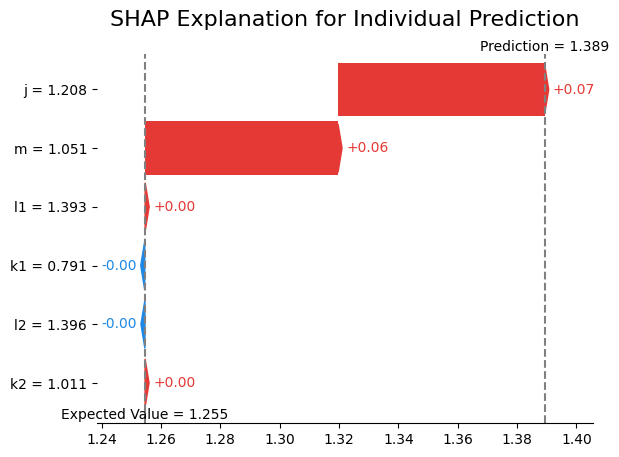

In [42]:
# Plot SHAP Single Waterfall Plot
# The 'plot_shap_single_waterfall' method generates a SHAP waterfall plot for a single test sample,
# visualizing how each feature contributes to the model's prediction for that sample.
# - q_sample_df: A DataFrame containing the sample data (e.g., a specific parameter set) for which the SHAP values are calculated.
# - param_name: The name of the quantity of interest (QoI) being analyzed ('t_1' in this case).
# The SHAP waterfall plot shows the cumulative effect of each feature on the model's prediction, helping to interpret individual predictions.
fig = await model.plot_shap_single_waterfall(X_test, silent=True, q=q_true_df, param_name='f.1')

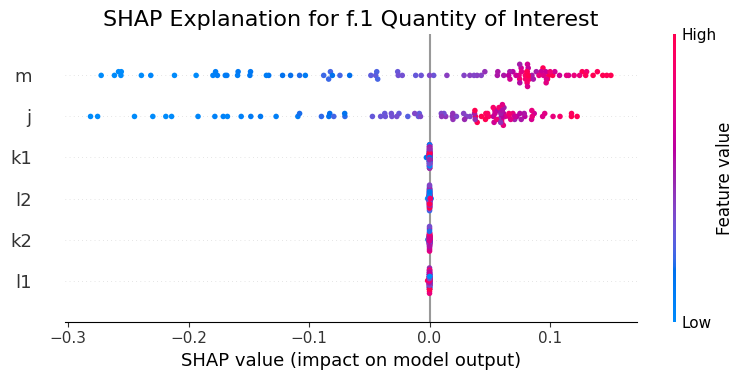

In [43]:
# Plot SHAP Beeswarm Plot
# The 'plot_shap_beeswarm' method generates a SHAP beeswarm plot, which visualizes the distribution of SHAP values
# for a range of test samples, showing the impact of each feature on the model’s predictions.
# - q: The test data (model.X_test.iloc[:100]) is selected for which SHAP values are calculated and visualized.
# - param_name: The name of the quantity of interest (QoI) for which SHAP values are computed ('t_1' in this case).
# The SHAP beeswarm plot shows how different input features influence the predictions across multiple samples,
# helping to understand the global feature importance and the relationships between features and the target.
fig = await model.plot_shap_beeswarm(X_test, silent=True, param_name='f.1')

In [44]:
# Make a prediction using the surrogate model
# - q_sample_df: A DataFrame containing the input parameter values for which the model will generate a prediction.
model.predict(q_true_df)

array([[ 1.38930174,  1.62931392,  0.91485565,  0.41079391, -0.41079391,
         0.91485565]])

In [45]:
qoi_m_df = pd.read_csv('mosaic_qoi_m_true_df_toy_6.csv')

In [46]:
# For Update
# The standard deviation of the error is computed using the statistics from the QoI DataFrame
sigma = QoI_df.describe().loc['std'] / 30  # Adjust standard deviation for each parameter in the QoI_df

# Generate the simulation parameter set (random noise) based on the updated measurement error (sigma)
E = generate_stndrn_variable_set(sigma.values.flatten())  # Generate random noise according to sigma values

# Set up the parameters for the Markov Chain Monte Carlo (MCMC) simulation
nwalkers = 16  # Number of walkers (parallel chains) in the MCMC process
nburn = 200  # Number of burn-in steps: these are discarded, as they help the MCMC chain reach equilibrium
niter = 50  # Total number of iterations for the MCMC process

In [47]:
# Initialize the Digital Twin model with the surrogate model and simulation parameter set (E)
DT = dt.DigitalTwin(model, E)  # Create a DigitalTwin instance that integrates the surrogate model and the random noise (E)

In [48]:
# Update the Digital Twin model with the synthetic measurement data and run MCMC sampling
DT.update(qoi_m_df, nwalkers=nwalkers, nburn=nburn, niter=niter)
# The 'update' method updates the Digital Twin using the synthetic measurement data (qoi_m_df)
# and performs MCMC sampling with the specified parameters (number of walkers, burn-in steps, and iterations)

MCMC creating
Burning period


100%|██████████| 200/200 [00:27<00:00,  7.21it/s]


MCMC running


100%|██████████| 50/50 [00:06<00:00,  7.21it/s]

--- 34.80920219421387 seconds ---


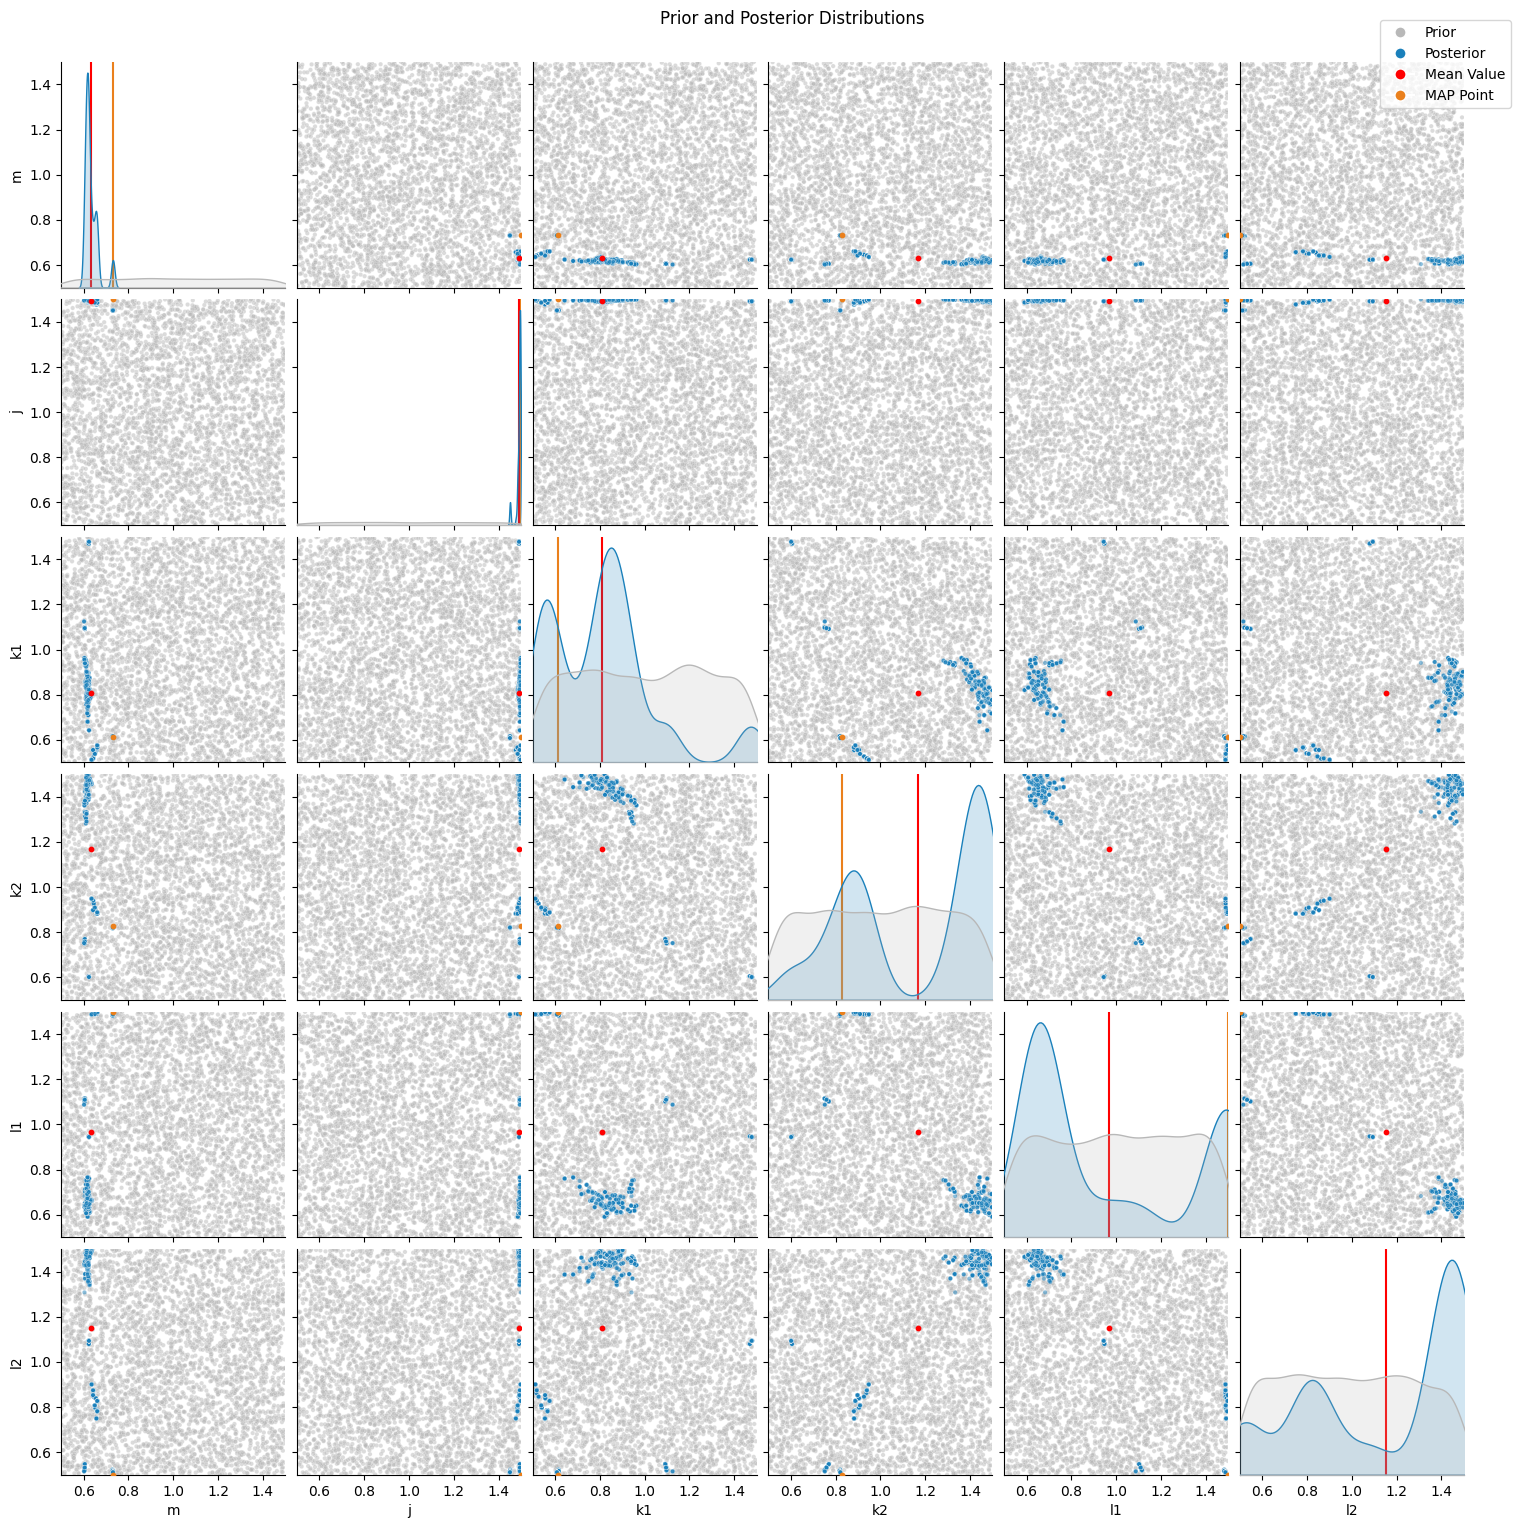

In [50]:
# Plot the MCMC sampling results along with the mean and MAP and true parameter values
fig = DT.plot_MCMC(X_train)